# R-hat trajectories: full-choice versus adaptive sampler

This notebook compares how the **rank-normalized split R-hat** for one coefficient evolves as progressively longer prefixes of the posterior are retained. Each panel is one `(J, N)` dataset configuration; the two curves use the corresponding full-choice and adaptive-sampler traces.

The supplied files each contain **four chains**. R-hat is never calculated after pooling chains: at a prefix of `t` draws per original chain, each chain is split in half, so the calculation uses `2 × 4 = 8` split chains of approximately `t / 2` draws. The x-axis is therefore *retained iterations per original chain*, not a total draw count.

In [1]:
from pathlib import Path
import re

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo_root = Path.cwd().resolve()
if not (repo_root / 'results').is_dir():
    repo_root = repo_root.parent
assert (repo_root / 'results').is_dir(), 'Start Jupyter from the repository root or results/'

adaptive_root = repo_root / 'results' / 'adaptive_sampler'
full_root = Path('/Users/preto/Documents/EPFL/PhD/projects/Bayesian/bayesian-choice-modeling-w-alt-sampling/results/results_pymc/full_C/p10')

configs = [(J, N) for J in (100, 200, 500) for N in (10_000, 20_000, 50_000)]
trace_paths = {}
for J, N in configs:
    config = f'J{J}_N{N}'
    adaptive = adaptive_root / f'trace_{config}_P10_prot2_mtm_steps5000_SCALE260313.nc'
    n_short = {10_000: '10k', 20_000: '20k', 50_000: '50k'}[N]
    # Only the J100/N10k full-choice file has the archival `~01` suffix.
    full_suffix = '~01.nc' if (J, N) == (100, 10_000) else '.nc'
    full = full_root / f'restaurants_mnl_P10_J{J}_N{n_short}_I0_C0_M0_woJIT{full_suffix}'
    trace_paths[config] = {'adaptive': adaptive, 'full-choice': full}

missing = [str(path) for paths in trace_paths.values() for path in paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError('Missing trace files:\n' + '\n'.join(missing))


## Controls

`check_every` trades resolution for computation. R-hat requires ranking all values in every prefix, so setting it to 50 evaluates about 120 prefixes for a 6,000-draw adaptive trace instead of 5,993. The final draw is always included even when it does not fall on this grid.

In [2]:
parameter_display = 'log_dist'
trace_display = 'all'  # 'all' or a configuration fragment, e.g. 'J100_N10000'
check_every = 10       # 1 recomputes R-hat at every retained iteration

# A rank-normalized split R-hat needs at least two chains and enough draws
# to split each chain. Eight original-chain draws gives four draws per split chain.
min_draws_per_chain = 8
rhat_thresholds = (1.01, 1.05)
rhat_threshold = 1.01
min_ess_bulk = 400
min_ess_tail = 400
mean_mcse_relative_tolerance = 0.02      # MCSE(mean) / posterior SD
endpoint_mcse_relative_tolerance = 0.05  # MCSE(2.5% or 97.5%) / posterior SD

# The compound adaptive sampler tunes its parameter-estimation step during the
# first 1,000 draws of each chain. These files retain those draws even though
# their NetCDF metadata reports tuning_steps=0, so exclude them explicitly.
# Full-choice posterior groups already exclude NUTS warmup.
tune_as = 1000

parameter = parameter_display if parameter_display.startswith('beta_') else f'beta_{parameter_display}'
if not isinstance(check_every, int) or check_every < 1:
    raise ValueError('check_every must be a positive integer')
if not isinstance(tune_as, int) or tune_as < 0:
    raise ValueError('tune_as must be a non-negative integer')
if min_ess_bulk < 1 or min_ess_tail < 1:
    raise ValueError('ESS thresholds must be positive')
if mean_mcse_relative_tolerance <= 0 or endpoint_mcse_relative_tolerance <= 0:
    raise ValueError('MCSE tolerances must be positive')


## What is computed

For each prefix, ArviZ's `method='rank'` implements the Vehtari et al. rank-normalized, folded, split R-hat. After splitting, let `m` be the number of split chains (here `m=8`) and `n` their common length. With within-chain variance `W` and between-chain variance `B = n Var(chain means)`, the basic form is `sqrt((((n - 1) / n) W + B / n) / W)`. Rank normalization makes the diagnostic robust to heavy tails; the reported diagnostic is the worse of the rank-normalized and folded versions.

A curve below 1.01 is evidence of mixing across these four chains, but it is not by itself a safe stopping rule: it does not establish Monte Carlo precision. At every checkpoint, the notebook therefore also calculates bulk/tail ESS and MCSE for the posterior mean and both 95% interval endpoints for **all** `beta_*` coefficients. `parameter_display` changes only what is plotted. The precision gate passes only when every coefficient meets the R-hat, ESS, and relative-MCSE thresholds in the controls; consider requiring that joint gate for several consecutive checks before stopping.

In [3]:
def scalar_metric(diagnostic, name):
    """Extract one scalar from an ArviZ Dataset diagnostic."""
    return float(np.asarray(diagnostic[name]).squeeze())

def regular_rhat_unsplit(draws, name):
    """Classical R-hat on raw, unsplit chains for one parameter."""
    values = np.asarray(draws[name].transpose('chain', 'draw').values, dtype=float)
    chains, draws_per_chain = values.shape
    chain_means = values.mean(axis=1)
    within_chain_variance = values.var(axis=1, ddof=1).mean()
    between_chain_variance = draws_per_chain * chain_means.var(ddof=1)
    variance_plus = ((draws_per_chain - 1) / draws_per_chain) * within_chain_variance + between_chain_variance / draws_per_chain
    return float(np.sqrt(variance_plus / within_chain_variance))

def retained_draws(path, estimator):
    idata = az.from_netcdf(path)
    parameters = sorted(name for name in idata.posterior.data_vars if name.startswith('beta_'))
    if parameter not in parameters:
        raise KeyError(f'{parameter!r} is not present in {path.name}')
    draws = idata.posterior[parameters]
    if set(('chain', 'draw')) - set(draws.dims):
        raise ValueError(f'{path.name}: expected chain and draw dimensions, got {draws.dims}')
    if estimator == 'adaptive':
        tuning_steps = int(idata.posterior.attrs.get('tuning_steps', 0))
        burnin = int(getattr(idata, 'sample_stats', {}).attrs.get('burnin', 0))
        if tune_as >= draws.sizes['draw']:
            raise ValueError(f'{path.name}: tune_as={tune_as} leaves no adaptive posterior draws.')
        print(f'{path.name}: adaptive metadata has tuning_steps={tuning_steps}, burnin={burnin}; discarding the first tune_as={tune_as} draws per chain.')
        draws = draws.isel(draw=slice(tune_as, None))
    return draws

selected = {config: paths for config, paths in trace_paths.items()
            if trace_display == 'all' or trace_display in config}
if not selected:
    raise ValueError(f'No configuration matched trace_display={trace_display!r}')

rows = []
for config, paths in selected.items():
    for estimator, path in paths.items():
        draws = retained_draws(path, estimator)
        n_chains, n_draws = (int(draws.sizes['chain']), int(draws.sizes['draw']))
        if n_chains < 2:
            raise ValueError(f'{path.name}: R-hat needs at least two chains; found {n_chains}.')
        if n_draws < min_draws_per_chain:
            raise ValueError(f'{path.name}: only {n_draws} retained draws per chain.')
        checks = np.unique(np.r_[np.arange(min_draws_per_chain, n_draws + 1, check_every), n_draws]).astype(int)
        print(f'{config:>13} | {estimator:>11}: {n_chains} chains × {n_draws} retained draws; {len(checks)} R-hat checks')
        for retained in checks:
            prefix = draws.isel(draw=slice(0, retained))
            rhat = az.rhat(prefix, method='rank')
            ess_bulk = az.ess(prefix, method='bulk')
            ess_tail = az.ess(prefix, method='tail')
            mcse_mean = az.mcse(prefix, method='mean')
            mcse_lower = az.mcse(prefix, method='quantile', prob=0.025)
            mcse_upper = az.mcse(prefix, method='quantile', prob=0.975)
            posterior_sd = prefix.std(dim=('chain', 'draw'), ddof=1)
            for name in prefix.data_vars:
                sd = scalar_metric(posterior_sd, name)
                mean_rel_mcse = scalar_metric(mcse_mean, name) / sd
                lower_rel_mcse = scalar_metric(mcse_lower, name) / sd
                upper_rel_mcse = scalar_metric(mcse_upper, name) / sd
                rhat_value = scalar_metric(rhat, name)
                regular_rhat_value = regular_rhat_unsplit(prefix, name)
                bulk_value = scalar_metric(ess_bulk, name)
                tail_value = scalar_metric(ess_tail, name)
                gate_pass = all(np.isfinite(value) for value in (rhat_value, bulk_value, tail_value, mean_rel_mcse, lower_rel_mcse, upper_rel_mcse)) and (
                    rhat_value <= rhat_threshold and bulk_value >= min_ess_bulk and tail_value >= min_ess_tail
                    and mean_rel_mcse <= mean_mcse_relative_tolerance
                    and max(lower_rel_mcse, upper_rel_mcse) <= endpoint_mcse_relative_tolerance
                )
                rows.append({
                    'configuration': config, 'estimator': estimator, 'parameter': name,
                    'chains': n_chains, 'iterations_per_chain': retained, 'split_chains': 2 * n_chains,
                    'r_hat': rhat_value, 'regular_r_hat': regular_rhat_value,
                    'ess_bulk': bulk_value, 'ess_tail': tail_value,
                    'posterior_sd': sd, 'mean_mcse_relative': mean_rel_mcse,
                    'lower_endpoint_mcse_relative': lower_rel_mcse,
                    'upper_endpoint_mcse_relative': upper_rel_mcse,
                    'parameter_gate_pass': gate_pass,
                })

rhat_trajectory = pd.DataFrame(rows)
checkpoint_keys = ['configuration', 'estimator', 'iterations_per_chain']
rhat_trajectory['all_parameters_gate_pass'] = rhat_trajectory.groupby(checkpoint_keys)['parameter_gate_pass'].transform('all')
rhat_display = rhat_trajectory.query('parameter == @parameter').copy()
display(rhat_display.head())


trace_J100_N10000_P10_prot2_mtm_steps5000_SCALE260313.nc: adaptive metadata has tuning_steps=0, burnin=0; discarding the first tune_as=1000 draws per chain.
  J100_N10000 |    adaptive: 4 chains × 5000 retained draws; 501 R-hat checks


/Users/preto/miniforge3/envs/bay/lib/python3.11/site-packages/arviz/stats/diagnostics.py:596: RuntimeWarning: divide by zero encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)


  J100_N10000 | full-choice: 4 chains × 500 retained draws; 51 R-hat checks
trace_J100_N20000_P10_prot2_mtm_steps5000_SCALE260313.nc: adaptive metadata has tuning_steps=0, burnin=0; discarding the first tune_as=1000 draws per chain.
  J100_N20000 |    adaptive: 4 chains × 5000 retained draws; 501 R-hat checks


/Users/preto/miniforge3/envs/bay/lib/python3.11/site-packages/arviz/stats/diagnostics.py:596: RuntimeWarning: divide by zero encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)


  J100_N20000 | full-choice: 4 chains × 1000 retained draws; 101 R-hat checks
trace_J100_N50000_P10_prot2_mtm_steps5000_SCALE260313.nc: adaptive metadata has tuning_steps=0, burnin=0; discarding the first tune_as=1000 draws per chain.
  J100_N50000 |    adaptive: 4 chains × 5000 retained draws; 501 R-hat checks
  J100_N50000 | full-choice: 4 chains × 500 retained draws; 51 R-hat checks
trace_J200_N10000_P10_prot2_mtm_steps5000_SCALE260313.nc: adaptive metadata has tuning_steps=0, burnin=0; discarding the first tune_as=1000 draws per chain.
  J200_N10000 |    adaptive: 4 chains × 5000 retained draws; 501 R-hat checks


/Users/preto/miniforge3/envs/bay/lib/python3.11/site-packages/arviz/stats/diagnostics.py:596: RuntimeWarning: divide by zero encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)


... (4 outputs left out)

  J200_N50000 | full-choice: 4 chains × 500 retained draws; 51 R-hat checks
trace_J500_N10000_P10_prot2_mtm_steps5000_SCALE260313.nc: adaptive metadata has tuning_steps=0, burnin=0; discarding the first tune_as=1000 draws per chain.
  J500_N10000 |    adaptive: 4 chains × 5000 retained draws; 501 R-hat checks
  J500_N10000 | full-choice: 4 chains × 500 retained draws; 51 R-hat checks
trace_J500_N20000_P10_prot2_mtm_steps5000_SCALE260313.nc: adaptive metadata has tuning_steps=0, burnin=0; discarding the first tune_as=1000 draws per chain.
  J500_N20000 |    adaptive: 4 chains × 5000 retained draws; 501 R-hat checks


/Users/preto/miniforge3/envs/bay/lib/python3.11/site-packages/arviz/stats/diagnostics.py:596: RuntimeWarning: divide by zero encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)


  J500_N20000 | full-choice: 4 chains × 500 retained draws; 51 R-hat checks
trace_J500_N50000_P10_prot2_mtm_steps5000_SCALE260313.nc: adaptive metadata has tuning_steps=0, burnin=0; discarding the first tune_as=1000 draws per chain.
  J500_N50000 |    adaptive: 4 chains × 5000 retained draws; 501 R-hat checks
  J500_N50000 | full-choice: 4 chains × 500 retained draws; 51 R-hat checks


,configuration,estimator,parameter,chains,iterations_per_chain,split_chains,r_hat,regular_r_hat,ess_bulk,ess_tail,posterior_sd,mean_mcse_relative,lower_endpoint_mcse_relative,upper_endpoint_mcse_relative,parameter_gate_pass,all_parameters_gate_pass
7,J100_N10000,adaptive,beta_log_dist,4,8,8,4.173397,4.921816,48.164799,32.000000,0.019821,0.144090,0.000000,0.104284,False,False
17,J100_N10000,adaptive,beta_log_dist,4,18,8,2.249504,1.574382,7.635027,6.786609,0.034519,0.377849,0.398709,0.000000,False,False
27,J100_N10000,adaptive,beta_log_dist,4,28,8,1.833919,1.334445,11.677100,6.325778,0.029724,0.321898,0.664275,0.000000,False,False
37,J100_N10000,adaptive,beta_log_dist,4,38,8,1.783507,1.377834,10.820326,5.682194,0.029833,0.333999,0.661858,0.096227,False,False
47,J100_N10000,adaptive,beta_log_dist,4,48,8,1.631900,1.267285,15.603070,7.324733,0.028413,0.263400,0.548902,0.101035,False,False


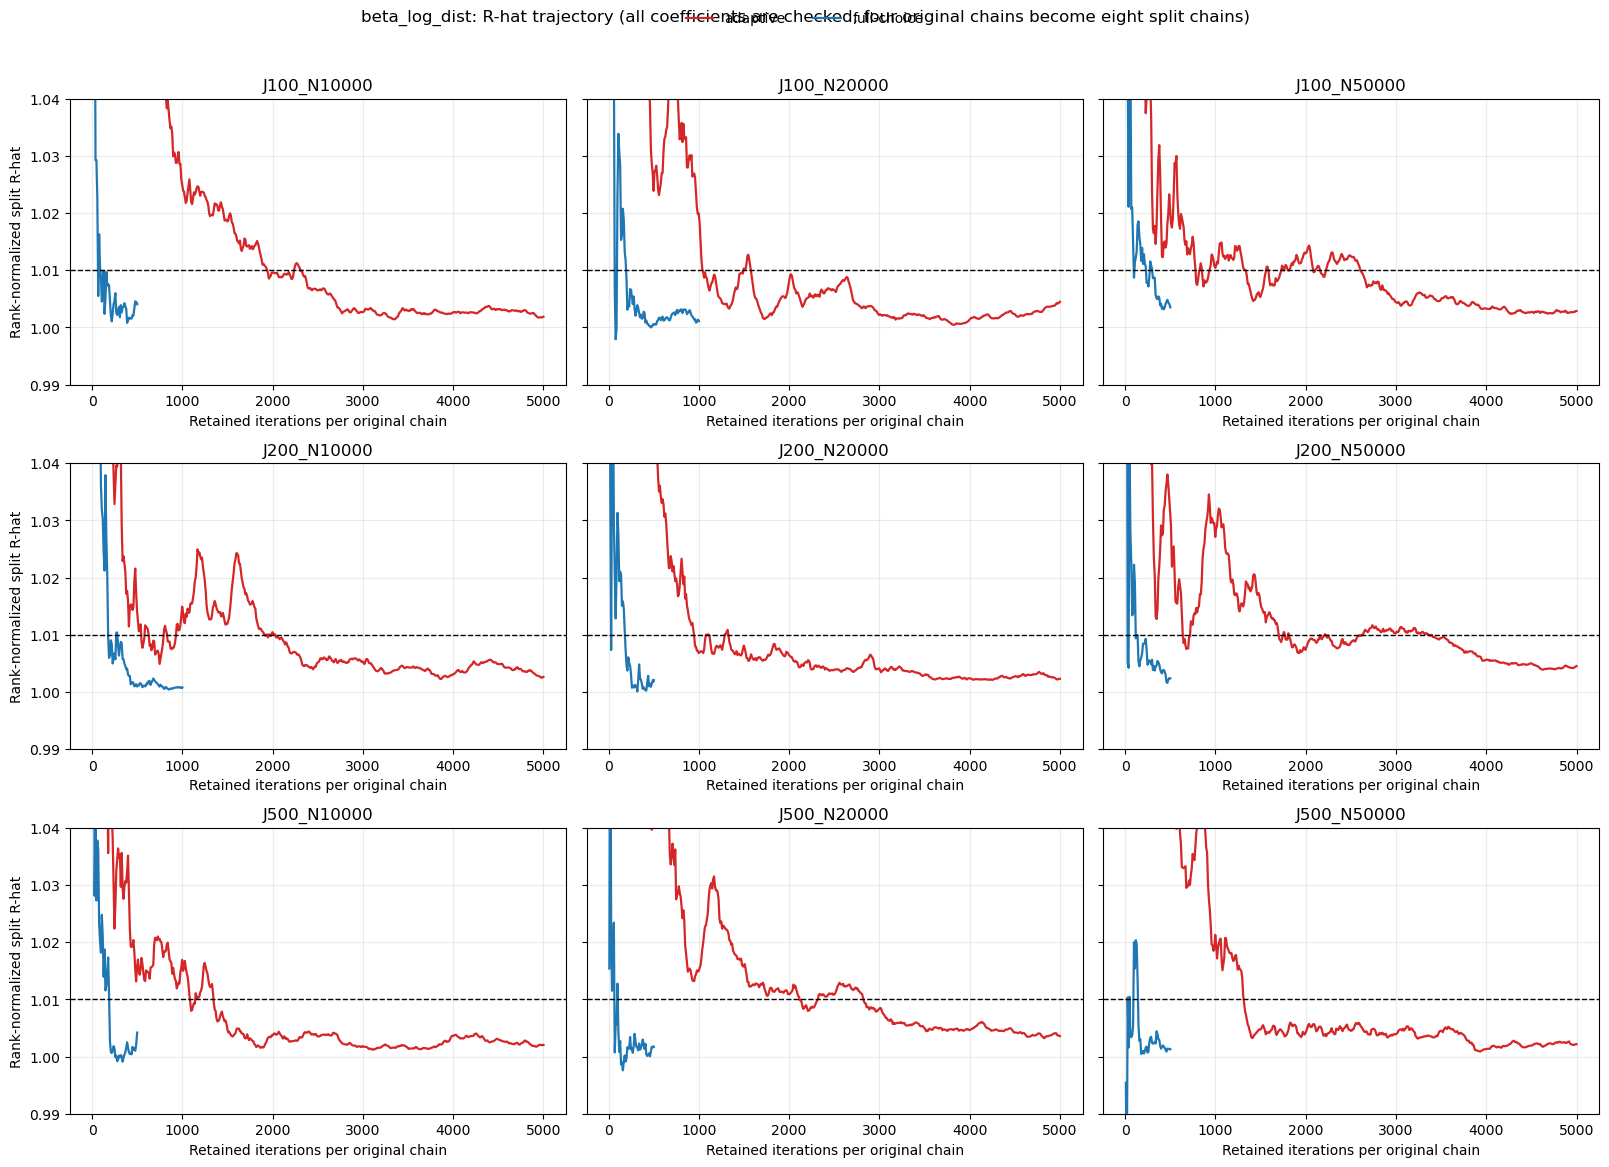

In [4]:
n_configs = len(selected)
ncols = min(3, n_configs)
nrows = int(np.ceil(n_configs / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.4 * ncols, 3.8 * nrows), squeeze=False, sharey=True)
colors = {'full-choice': '#1f77b4', 'adaptive': '#d62728'}

for ax, config in zip(axes.flat, sorted(selected)):
    panel = rhat_display.query('configuration == @config')
    for estimator, curve in panel.groupby('estimator', sort=False):
        ax.plot(curve['iterations_per_chain'], curve['r_hat'], label=estimator, color=colors[estimator], linewidth=1.6)
    for threshold in rhat_thresholds:
        ax.axhline(threshold, color='black', linestyle='--' if threshold == 1.01 else ':', linewidth=1)
    ax.set_title(config)
    ax.set_xlabel('Retained iterations per original chain')
    ax.grid(alpha=0.25)

for ax in axes[:, 0]:
    ax.set_ylabel('Rank-normalized split R-hat')
    ax.set_ylim(0.99,1.04)
for ax in axes.flat[n_configs:]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, frameon=False)
fig.suptitle(f'{parameter}: R-hat trajectory (all coefficients are checked; four original chains become eight split chains)', y=1.02)
fig.tight_layout()
plt.show()


In [5]:
# The table displays the selected parameter, while all_parameters_gate_pass is
# evaluated jointly over every beta coefficient at the same checkpoint.
summary_rows = []
for (config, estimator), curve in rhat_display.groupby(['configuration', 'estimator'], sort=True):
    row = {
        'configuration': config, 'estimator': estimator,
        'chains': int(curve['chains'].iloc[0]), 'split_chains': int(curve['split_chains'].iloc[0]),
        'final_iterations_per_chain': int(curve['iterations_per_chain'].iloc[-1]),
        'final_r_hat': curve['r_hat'].iloc[-1],
        'final_ess_bulk': curve['ess_bulk'].iloc[-1],
        'final_ess_tail': curve['ess_tail'].iloc[-1],
        'final_mean_mcse_relative': curve['mean_mcse_relative'].iloc[-1],
        'final_endpoint_mcse_relative': curve[['lower_endpoint_mcse_relative', 'upper_endpoint_mcse_relative']].iloc[-1].max(),
        'selected_parameter_gate_pass': bool(curve['parameter_gate_pass'].iloc[-1]),
        'all_parameters_gate_pass': bool(curve['all_parameters_gate_pass'].iloc[-1]),
    }
    for threshold in rhat_thresholds:
        hits = curve.loc[curve['r_hat'] <= threshold, 'iterations_per_chain']
        row[f'first_checked_rhat_le_{threshold:.2f}'] = int(hits.iloc[0]) if not hits.empty else pd.NA
    all_gate_hits = curve.loc[curve['all_parameters_gate_pass'], 'iterations_per_chain']
    row['first_checked_all_parameters_gate'] = int(all_gate_hits.iloc[0]) if not all_gate_hits.empty else pd.NA
    summary_rows.append(row)

rhat_summary = pd.DataFrame(summary_rows)
display(rhat_summary)


,configuration,estimator,chains,split_chains,final_iterations_per_chain,final_r_hat,final_ess_bulk,final_ess_tail,final_mean_mcse_relative,final_endpoint_mcse_relative,selected_parameter_gate_pass,all_parameters_gate_pass,first_checked_rhat_le_1.01,first_checked_rhat_le_1.05,first_checked_all_parameters_gate
0,J100_N10000,adaptive,4,8,5000,1.001851,2700.532489,2194.805839,0.019160,0.050002,False,False,1948,508,<NA>
1,J100_N10000,full-choice,4,8,500,1.004026,1267.754717,1097.603492,0.028060,0.100994,False,False,68,38,<NA>
2,J100_N20000,adaptive,4,8,5000,1.004469,2582.975922,2273.440417,0.019611,0.055113,False,False,1048,418,<NA>
3,J100_N20000,full-choice,4,8,1000,1.001089,2864.120012,2889.723192,0.018682,0.043895,True,False,68,28,<NA>
4,J100_N50000,adaptive,4,8,5000,1.002855,2076.292291,1602.002967,0.021755,0.075390,False,False,788,188,<NA>
5,J100_N50000,full-choice,4,8,500,1.003493,1354.881125,1235.672368,0.027278,0.097785,False,False,98,28,<NA>
6,J200_N10000,adaptive,4,8,5000,1.002628,2368.290645,2075.084432,0.020483,0.059379,False,False,548,228,<NA>
7,J200_N10000,full-choice,4,8,1000,1.000778,2883.674566,2716.115492,0.018618,0.048972,True,False,178,98,<NA>
8,J200_N20000,adaptive,4,8,5000,1.002297,2403.744186,2230.492787,0.020286,0.065204,False,False,948,378,<NA>
9,J200_N20000,full-choice,4,8,500,1.002079,1097.999966,998.115477,0.030103,0.069107,False,False,28,18,<NA>


In [6]:
rhat_trajectory.to_csv('convergence_per_param_per_estimator_per_10iter.csv')
rhat_trajectory

,configuration,estimator,parameter,chains,iterations_per_chain,split_chains,r_hat,regular_r_hat,ess_bulk,ess_tail,posterior_sd,mean_mcse_relative,lower_endpoint_mcse_relative,upper_endpoint_mcse_relative,parameter_gate_pass,all_parameters_gate_pass
0,J100_N10000,adaptive,beta_chinese,4,8,8,2.693058,1.245625,48.164799,32.000000,0.050939,0.144090,1.723819,0.000000,False,False
1,J100_N10000,adaptive,beta_cost,4,8,8,5.705403,1.266569,48.164799,48.164799,0.002935,0.144090,0.000000,0.065925,False,False
2,J100_N10000,adaptive,beta_french,4,8,8,2.626439,1.572514,48.164799,32.000000,0.084026,0.144090,0.000000,0.000000,False,False
3,J100_N10000,adaptive,beta_indian,4,8,8,1.601019,1.327947,48.164799,48.164799,0.136782,0.144090,0.000000,0.637778,False,False
4,J100_N10000,adaptive,beta_japanese,4,8,8,inf,6.424943,48.164799,32.000000,0.075306,0.144090,0.000000,0.000000,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50675,J500_N50000,full-choice,beta_korean,4,500,8,1.013438,1.010497,410.560220,594.426082,0.028804,0.049315,0.068622,0.117193,False,False
50676,J500_N50000,full-choice,beta_lebanese,4,500,8,1.013423,1.009363,406.519585,566.034873,0.027128,0.049351,0.115644,0.128661,False,False
50677,J500_N50000,full-choice,beta_log_dist,4,500,8,1.001256,1.001587,1290.743365,1067.330752,0.005589,0.027994,0.093799,0.103775,False,False
50678,J500_N50000,full-choice,beta_mexican,4,500,8,1.016617,1.011701,367.132176,529.511010,0.025747,0.052109,0.108421,0.150377,False,False


In [7]:
parameter_display = 'japanese'
parameter = (
    parameter_display
    if parameter_display.startswith('beta_')
    else f'beta_{parameter_display}'
)

rhat_display = rhat_trajectory.query('parameter == @parameter').copy()

summary_rows = []
for (config, estimator), curve in rhat_display.groupby(
    ['configuration', 'estimator'], sort=True
):
    row = {
        'configuration': config,
        'estimator': estimator,
        'chains': int(curve['chains'].iloc[0]),
        'split_chains': int(curve['split_chains'].iloc[0]),
        'final_iterations_per_chain': int(curve['iterations_per_chain'].iloc[-1]),
        'final_r_hat': curve['r_hat'].iloc[-1],
        'final_ess_bulk': curve['ess_bulk'].iloc[-1],
        'final_ess_tail': curve['ess_tail'].iloc[-1],
        'final_mean_mcse_relative': curve['mean_mcse_relative'].iloc[-1],
        'final_endpoint_mcse_relative': curve[
            ['lower_endpoint_mcse_relative', 'upper_endpoint_mcse_relative']
        ].iloc[-1].max(),
        'selected_parameter_gate_pass': bool(curve['parameter_gate_pass'].iloc[-1]),
        'all_parameters_gate_pass': bool(curve['all_parameters_gate_pass'].iloc[-1]),
    }

    for threshold in rhat_thresholds:
        hits = curve.loc[
            curve['r_hat'] <= threshold, 'iterations_per_chain'
        ]
        row[f'first_checked_rhat_le_{threshold:.2f}'] = (
            int(hits.iloc[0]) if not hits.empty else pd.NA
        )

    all_gate_hits = curve.loc[
        curve['all_parameters_gate_pass'], 'iterations_per_chain'
    ]
    row['first_checked_all_parameters_gate'] = (
        int(all_gate_hits.iloc[0]) if not all_gate_hits.empty else pd.NA
    )
    summary_rows.append(row)

rhat_summary = pd.DataFrame(summary_rows)
display(rhat_summary)

,configuration,estimator,chains,split_chains,final_iterations_per_chain,final_r_hat,final_ess_bulk,final_ess_tail,final_mean_mcse_relative,final_endpoint_mcse_relative,selected_parameter_gate_pass,all_parameters_gate_pass,first_checked_rhat_le_1.01,first_checked_rhat_le_1.05,first_checked_all_parameters_gate
0,J100_N10000,adaptive,4,8,5000,1.013288,156.789076,389.891899,0.080110,0.088060,False,False,<NA>,1028,<NA>
1,J100_N10000,full-choice,4,8,500,1.012159,410.192218,607.050557,0.049574,0.146627,False,False,298,98,<NA>
2,J100_N20000,adaptive,4,8,5000,1.032544,117.269332,252.665140,0.092492,0.136030,False,False,<NA>,2818,<NA>
3,J100_N20000,full-choice,4,8,1000,1.008636,812.375341,1045.211614,0.035115,0.084315,False,False,228,68,<NA>
4,J100_N50000,adaptive,4,8,5000,1.037920,123.499468,290.004610,0.090114,0.161539,False,False,<NA>,3068,<NA>
5,J100_N50000,full-choice,4,8,500,1.015809,289.876889,565.370162,0.058265,0.102962,False,False,<NA>,158,<NA>
6,J200_N10000,adaptive,4,8,5000,1.037097,94.196113,267.754112,0.102862,0.185728,False,False,<NA>,3638,<NA>
7,J200_N10000,full-choice,4,8,1000,1.002923,753.136668,1239.629188,0.036446,0.069435,False,False,238,88,<NA>
8,J200_N20000,adaptive,4,8,5000,1.016091,89.174052,220.498709,0.106184,0.137485,False,False,<NA>,4298,<NA>
9,J200_N20000,full-choice,4,8,500,1.001322,367.417803,484.277231,0.052564,0.155497,False,False,368,68,<NA>


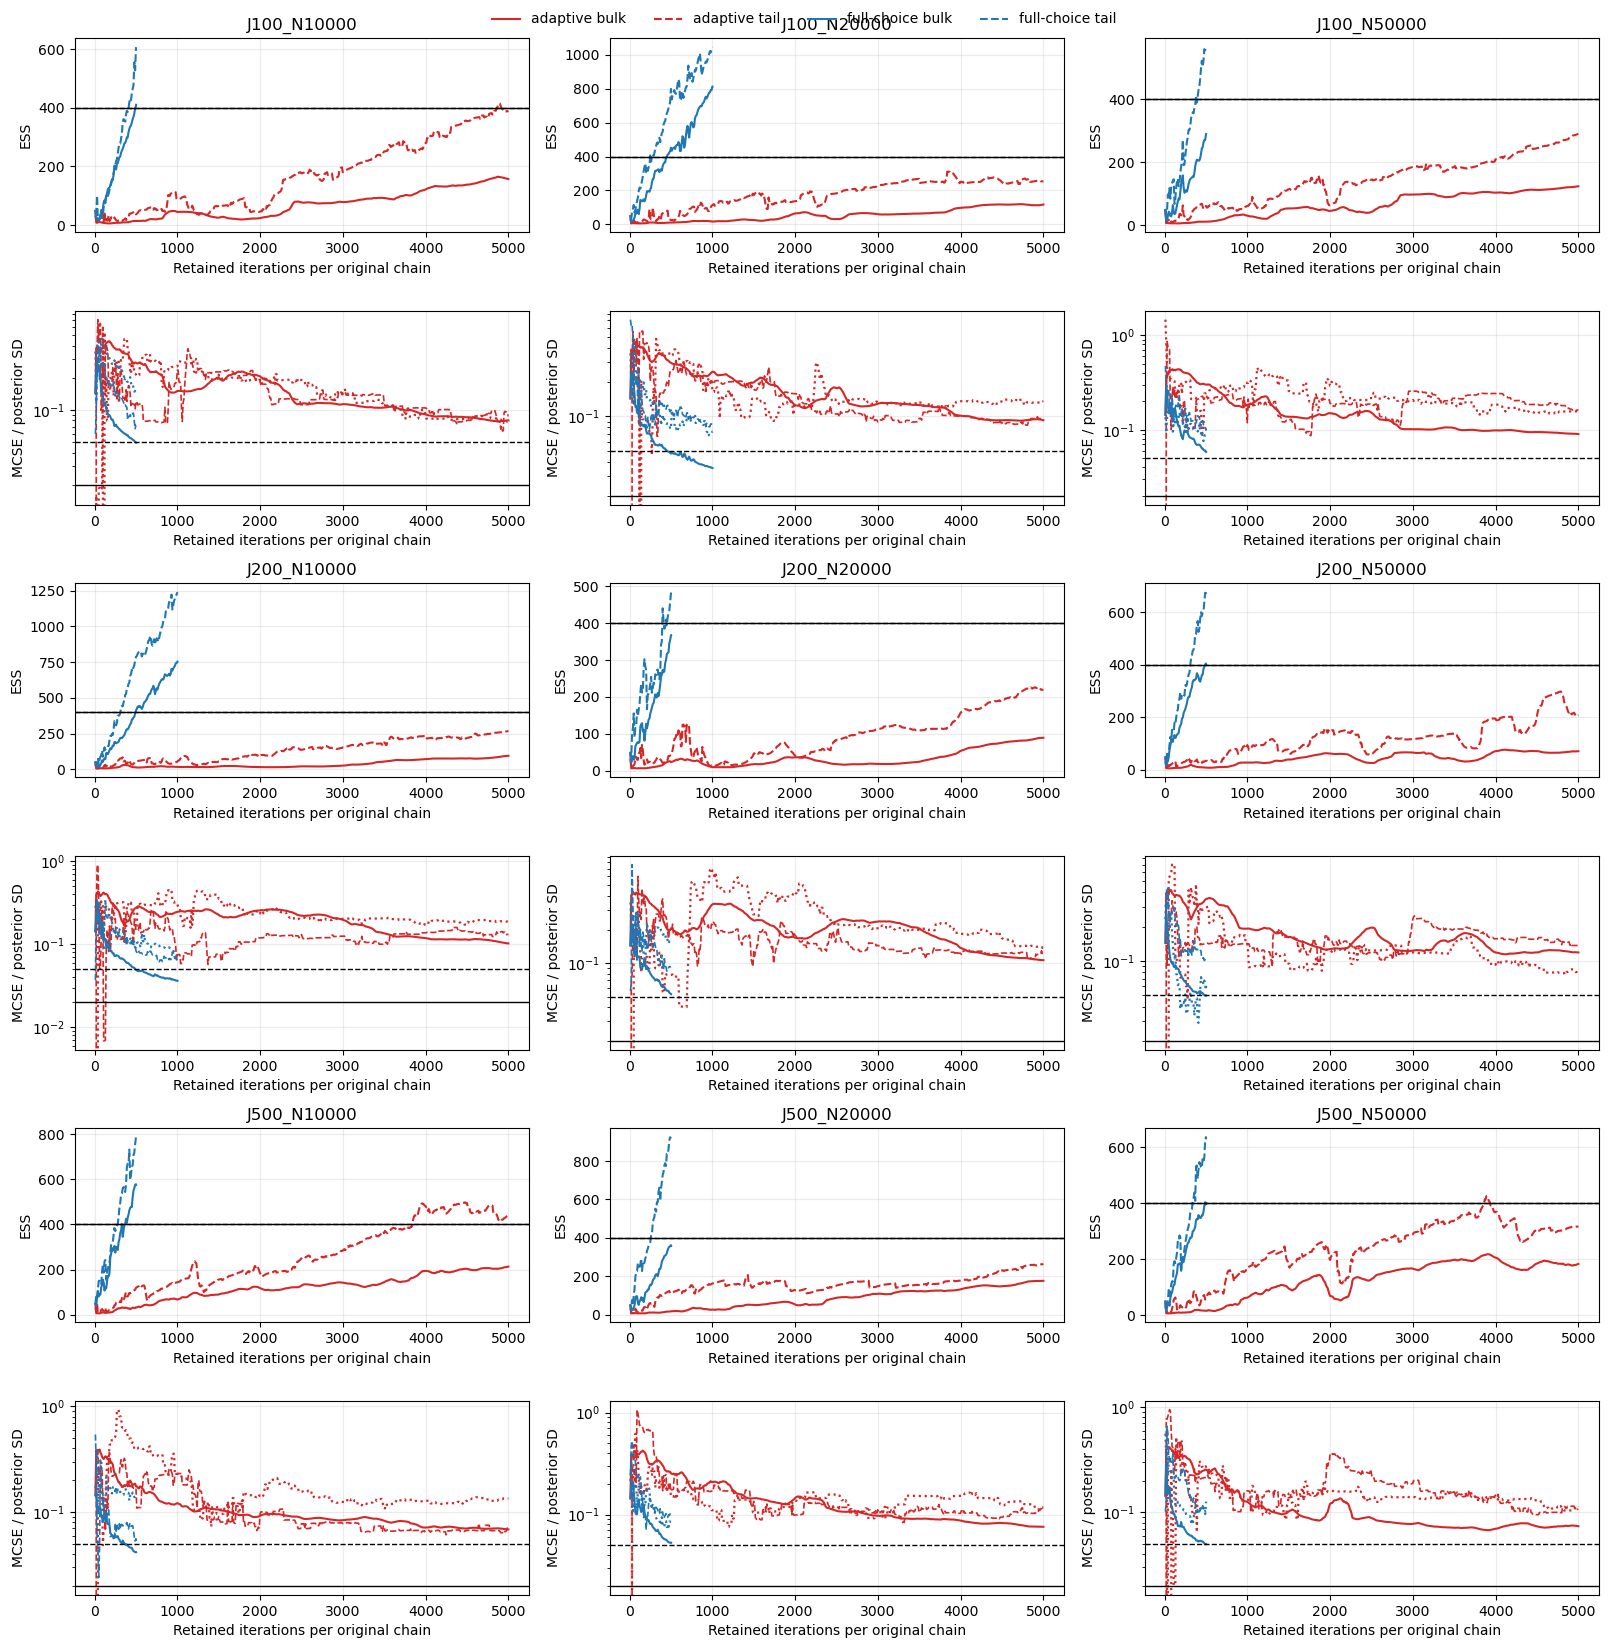

In [8]:
# ESS and precision trajectories for parameter_display. The calculations above
# nevertheless include every beta, and the bottom-row markers indicate the first
# checkpoint at which *all* beta coefficients pass the complete gate.
fig, axes = plt.subplots(2 * nrows, ncols, figsize=(5.4 * ncols, 5.5 * nrows), squeeze=False)
for index, config in enumerate(sorted(selected)):
    row, col = divmod(index, ncols)
    ax_ess, ax_mcse = axes[2 * row, col], axes[2 * row + 1, col]
    panel = rhat_display.query('configuration == @config')
    for estimator, curve in panel.groupby('estimator', sort=False):
        color = colors[estimator]
        x = curve['iterations_per_chain']
        ax_ess.plot(x, curve['ess_bulk'], color=color, linewidth=1.5, label=f'{estimator} bulk')
        ax_ess.plot(x, curve['ess_tail'], color=color, linestyle='--', linewidth=1.5, label=f'{estimator} tail')
        ax_mcse.plot(x, curve['mean_mcse_relative'], color=color, linewidth=1.5, label=f'{estimator} mean')
        ax_mcse.plot(x, curve['lower_endpoint_mcse_relative'], color=color, linestyle='--', linewidth=1.2, label=f'{estimator} 2.5%')
        ax_mcse.plot(x, curve['upper_endpoint_mcse_relative'], color=color, linestyle=':', linewidth=1.6, label=f'{estimator} 97.5%')
        first_all_pass = curve.loc[curve['all_parameters_gate_pass'], 'iterations_per_chain']
        if not first_all_pass.empty:
            ax_mcse.axvline(first_all_pass.iloc[0], color=color, alpha=0.30, linewidth=2)
    ax_ess.axhline(min_ess_bulk, color='black', linewidth=1, linestyle='-')
    ax_ess.axhline(min_ess_tail, color='black', linewidth=1, linestyle='--')
    ax_ess.set_title(config)
    ax_ess.set_xlabel('Retained iterations per original chain')
    ax_ess.set_ylabel('ESS')
    ax_ess.grid(alpha=0.25)
    ax_mcse.axhline(mean_mcse_relative_tolerance, color='black', linewidth=1, linestyle='-')
    ax_mcse.axhline(endpoint_mcse_relative_tolerance, color='black', linewidth=1, linestyle='--')
    ax_mcse.set_yscale('log')
    ax_mcse.set_xlabel('Retained iterations per original chain')
    ax_mcse.set_ylabel('MCSE / posterior SD')
    ax_mcse.grid(alpha=0.25)

for index in range(n_configs, nrows * ncols):
    row, col = divmod(index, ncols)
    axes[2 * row, col].set_visible(False)
    axes[2 * row + 1, col].set_visible(False)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, frameon=False)
# fig.suptitle(f'{parameter}: ESS and relative MCSE trajectories; vertical lines = first all-parameter pass', y=1.05)
fig.tight_layout()
plt.show()


In [10]:
# First checkpoint at which all three continuous parameters pass:
#   rank-normalized split R-hat <= 1.01
#   bulk ESS >= 400
#   tail ESS >= 400

continuous_params = ["beta_cost", "beta_rating", "beta_log_dist"]

# Keep "r_hat" for the recommended rank-normalized split R-hat.
# Change to "regular_r_hat" only if you explicitly want the classical raw,
# unsplit R-hat diagnostic instead.
rhat_column = "r_hat"

checks = (
    rhat_trajectory
    .query("parameter in @continuous_params")
    .copy()
)

checks["passes_three_checks"] = (
    np.isfinite(checks[rhat_column])
    & np.isfinite(checks["ess_bulk"])
    & np.isfinite(checks["ess_tail"])
    & (checks[rhat_column] <= rhat_threshold)
    & (checks["ess_bulk"] >= min_ess_bulk)
    & (checks["ess_tail"] >= min_ess_tail)
)

checkpoint_passes = (
    checks
    .groupby(["configuration", "estimator", "iterations_per_chain"])
    .agg(
        n_parameters=("parameter", "nunique"),
        passes_three_checks=("passes_three_checks", "all"),
    )
    .reset_index()
)

# A configuration-estimator can pass only if all three target parameters exist.
checkpoint_passes["passes_three_checks"] &= (
    checkpoint_passes["n_parameters"] == len(continuous_params)
)

first_pass = (
    checkpoint_passes
    .query("passes_three_checks")
    .groupby(["configuration", "estimator"], as_index=False)
    .agg(first_passing_iteration=("iterations_per_chain", "min"))
)

# Include pairs that never pass.
all_pairs = (
    rhat_trajectory[["configuration", "estimator"]]
    .drop_duplicates()
    .sort_values(["configuration", "estimator"])
)

three_check_summary = (
    all_pairs
    .merge(first_pass, on=["configuration", "estimator"], how="left")
    .sort_values(["configuration", "estimator"])
)

three_check_summary["first_passing_iteration"] = (
    three_check_summary["first_passing_iteration"].astype("Int64")
)

display(three_check_summary)

,configuration,estimator,first_passing_iteration
0,J100_N10000,adaptive,1948
1,J100_N10000,full-choice,198
2,J100_N20000,adaptive,2068
3,J100_N20000,full-choice,198
4,J100_N50000,adaptive,2658
5,J100_N50000,full-choice,248
6,J200_N10000,adaptive,2048
7,J200_N10000,full-choice,178
8,J200_N20000,adaptive,2058
9,J200_N20000,full-choice,308
